## 0. Librerías y carga de datos



In [ ]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dateutil.easter import easter
import holidays

from google.colab import drive
drive.mount('/content/drive')

CARPETA = '/content/drive/MyDrive/TFM'
RUTA = f'{CARPETA}/Data_Gripe.csv'
SALIDA = f'{CARPETA}/serie_diaria_con_calendario.csv'


# PARTE 1. Pre-procesado necesario para el primer LSTM

El primer LSTM solo necesita la fecha (en días consecutivos) y el número de casos. En esta parte se construye esa serie y se crean las etiquetas de semana ISO, temporada y periodo.

## 1. Carga y comprobaciones iniciales

Leemos solo las columnas que nos hacen falta para el modelo univariante: `data`, `casos` y `diagnostic`. Comprobamos que:
- `diagnostic` solo tiene el valor `Grip`.
- Cuál es el rango de fechas.
- Cuántos días distintos tienen alguna fila y cuántos días hay en el rango. La diferencia son las fechas que no aparecen en ninguna fila.
- La fecha se lee con `format='%d/%m/%Y'`


In [ ]:
raw = pd.read_csv(RUTA, usecols=['data', 'casos', 'diagnostic'])
raw['fecha'] = pd.to_datetime(raw['data'], format='%d/%m/%Y')

print('Filas y columnas:', raw.shape)
print('Diagnósticos:', raw['diagnostic'].unique())
print('Mínimo de casos por fila:', raw['casos'].min())
print('Primera fecha:', raw['fecha'].min().date(), '| última:', raw['fecha'].max().date())

dias_distintos = raw['fecha'].nunique()
rango_dias = (raw['fecha'].max() - raw['fecha'].min()).days + 1

print('Días distintos con alguna fila:', dias_distintos)
print('Días entre la primera y la última fecha:', rango_dias)
print('Días sin ninguna fila:', rango_dias - dias_distintos)

Filas y columnas: (1651237, 4)
Diagnósticos: <StringArray>
['Grip']
Length: 1, dtype: str
Mínimo de casos por fila: 1
Primera fecha: 2011-10-03 | última: 2026-09-27
Días distintos con alguna fila: 5433
Días entre la primera y la última fecha: 5474
Días sin ninguna fila: 41


## 2. Serie diaria total

Para el modelo base solo queremos la fecha y el total de casos, así que sumamos los casos de todas las filas de cada día. Comprobamos que la suma de la serie diaria es igual al total de casos del CSV.

In [ ]:
gripe_dia = raw.groupby('fecha')['casos'].sum()

print('Suma en el CSV:', raw['casos'].sum(), '| suma de la serie diaria:', gripe_dia.sum())
assert raw['casos'].sum() == gripe_dia.sum()

Suma en el CSV: 1875930 | suma de la serie diaria: 1875930


### 2.1 Calendario completo y huecos

Una LSTM da por hecho que cada paso de la secuencia es un día, por lo tanto hay que reindexar la serie a un calendario diario completo con días consecutivos.  Los días que no tenían fila quedan como huecos (NaN) y hay que decidir qué hacer con ellos.

In [ ]:
df = gripe_dia.to_frame(name='casos')
idx = pd.date_range(df.index.min(), df.index.max(), freq='D')
df = df.reindex(idx)
df.index.name = 'fecha'
df['valido'] = df['casos'].notna()

# Nº de huecos y longitud de cada tramo de días seguidos
falta = ~df['valido']
tramo = (falta != falta.shift()).cumsum()
tramos = df[falta].groupby(tramo[falta]).size()
print('Huecos:', int(falta.sum()), '| tramos:', len(tramos))
print('Longitud de los tramos (días: nº de tramos):', tramos.value_counts().sort_index().to_dict())

Huecos: 41 | tramos: 36
Longitud de los tramos (días: nº de tramos): {1: 31, 2: 5}


Faltan 41 días, repartidos en 31 tramos de 1 día y 5 tramos de 2 días.

### 2.2 Caracterización de los huecos

Para cada hueco miramos:
- Qué día de la semana es y si es festivo o laborable en Cataluña. Lo comprobamos porque los fines de semana y festivos tienen muy pocos diagnósticos, así que un día con 0 casos es posible.
- Si cae en pandemia (septiembre de 2019 a agosto de 2022) o fuera.
- La media de casos de los 7 días de alrededor (`ref7`). Si el nivel alrededor es bajo, un 0 es creíble. Si fuera alto, sospecharíamos que se ha perdido el dato.

In [ ]:
ref7 = df['casos'].rolling(7, center=True, min_periods=4).mean()

fest = holidays.Spain(subdiv='CT', years=range(df.index.min().year, df.index.max().year + 1))
h = df[falta].copy()
h['dia_semana'] = h.index.day_name()
h['finde'] = h.index.dayofweek >= 5
h['festivo'] = h.index.isin(pd.to_datetime(list(fest.keys())))
h['pandemia'] = (h.index >= '2019-09-01') & (h.index < '2022-09-01')
semana = h.index.isocalendar().week.to_numpy()
h['en_temporada'] = (semana >= 40) | (semana <= 20)
h['ref7'] = ref7.reindex(h.index)
h['motivo'] = np.select([h['finde'], h['festivo']], ['fin de semana', 'festivo entre semana'],
                        default='laborable')

print('Huecos por motivo y periodo pandémico:')
print(pd.crosstab(h['motivo'], h['pandemia'].map({True: 'En pandemia', False: 'Fuera de pandemia'})))
print('\nHuecos dentro de temporada (semanas 40-20):')
print(h.loc[h['en_temporada'], ['dia_semana', 'motivo', 'pandemia', 'ref7']].round(2))

Huecos por motivo y periodo pandémico:
pandemia              En pandemia  Fuera de pandemia
motivo                                              
festivo entre semana            2                  1
fin de semana                  16                 15
laborable                       7                  0

Huecos dentro de temporada (semanas 40-20):
           dia_semana                motivo  pandemia   ref7
fecha                                                       
2012-05-20     Sunday         fin de semana     False  17.83
2020-04-29  Wednesday             laborable      True   5.00
2020-05-01     Friday  festivo entre semana      True   6.25
2020-05-02   Saturday         fin de semana      True   6.50
2020-05-09   Saturday         fin de semana      True   2.50
2020-05-17     Sunday         fin de semana      True   2.17
2020-11-07   Saturday         fin de semana      True  17.33


Los huecos son aislados (1 o 2 días) y casi todos caen en fin de semana o festivo. Los pocos que caen en un laborable normal están en pandemia, cuando la actividad era muy baja. El nivel de alrededor es bajo en todos (el más alto es de unos 17 casos/día, en un sábado y un domingo).

Lo vemos en gráficos:

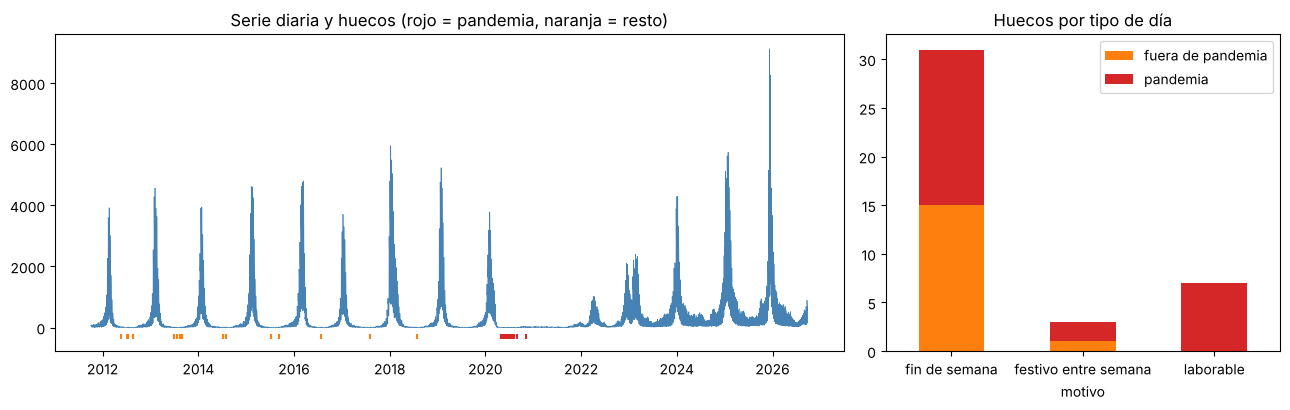

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [2, 1]})

# serie diaria con los huecos marcados
ax[0].plot(df.index, df['casos'].where(df['casos'] > 0), lw=.5, color='steelblue')
ax[0].scatter(h.index, np.full(len(h), -300), c=np.where(h['pandemia'], 'tab:red', 'tab:orange'), s=14, marker='|')
ax[0].set_title('Serie diaria y huecos (rojo = pandemia, naranja = resto)')

# huecos por tipo de día
orden = ['fin de semana', 'festivo entre semana', 'laborable']
tab = pd.crosstab(h['motivo'], h['pandemia']).reindex(orden).fillna(0)
tab.columns = ['fuera de pandemia' if not c else 'pandemia' for c in tab.columns]
tab.plot.bar(stacked=True, ax=ax[1], color=['tab:orange', 'tab:red'], rot=0)
ax[1].set_title('Huecos por tipo de día')

plt.tight_layout(); plt.show()

### 2.3 Decisión: cómo se rellenan los huecos

Según el nivel de referencia (`ref7`, la media de los 7 días que rodean al hueco):
- Si `ref7` es menor de 20 casos/día, el hueco se pasa a 0: con tan poca actividad un día sin casos es creíble.
- Si `ref7` es de 20 o más, un 0 no sería creíble y el hueco se rellena con esa media de los 7 días que lo rodean (redondeada a un número entero de casos).



In [ ]:
umbral = 20
a_cero = falta & (ref7 < umbral)       # nivel de alrededor bajo, pasan a 0
a_media = falta & ~(ref7 < umbral)     # nivel de alrededor alto, se hace la media
print(f'Huecos a 0: {int(a_cero.sum())} | huecos con la media de alrededor: {int(a_media.sum())} | total: {int(falta.sum())}')

df.loc[a_cero, 'casos'] = 0
# ref7 es la media de los 7 días centrados en el hueco (sin contar el propio hueco, que está vacío)
df.loc[a_media, 'casos'] = ref7[a_media].round()
casos_anadidos = int(df.loc[a_media, 'casos'].sum())
assert df['casos'].isna().sum() == 0, 'quedan huecos sin resolver'


Huecos a 0: 41 | huecos con la media de alrededor: 0 | total: 41


## 3. Semana ISO, temporada y periodo

Estas etiquetas no son variables de entrada del modelo. Las definimos ahora para dos cosas: evaluar el pico de cada temporada y definir los escenarios (antes, durante y después de la pandemia).

- **Semana ISO** semana 1 es la que contiene el primer jueves del año. Python la calcula con `isocalendar()`. Comprobamos que coincide con la semana epidemiológica de SIVIC.
- **Temporada**: de la semana ISO 40 a la 20 del año siguiente. La etiquetamos con el año ISO y no con el año natural, porque por ejemplo el 31/12/2012 pertenece a la semana 1 de 2013 y con el año natural quedaría en otra temporada.
- **Periodo**: pre-pandemia (hasta agosto de 2019), pandemia (septiembre de 2019 a agosto de 2022) y post-pandemia.

Recordemos que días fuera de la temporada quedan con `temporada` vacía, pero se mantienen en la serie y el modelo también aprende de ellos.

In [ ]:
iso = df.index.isocalendar()
df['semana_iso'] = iso['week'].to_numpy()
df['en_temporada'] = ((df['semana_iso'] >= 40) | (df['semana_iso'] <= 20)).astype(int)
inicio = np.where(df['semana_iso'] >= 40, iso['year'].to_numpy(), iso['year'].to_numpy() - 1)
df['temporada'] = [f'{a}-{str(a + 1)[2:]}' if t else None
                   for a, t in zip(inicio, df['en_temporada'])]

# Definición de periodo pre-pandémico, pandémico y post-pandémico
df['periodo'] = np.select([df.index < '2019-09-01', df.index < '2022-09-01'],
                          ['pre', 'pandemia'], default='post')

# comprobación de que la semana ISO coincide con la semana epidemiológica de SIVIC
sem = pd.read_csv(RUTA, usecols=['data', 'setmana_epidemiologica'])
sem['fecha'] = pd.to_datetime(sem['data'], format='%d/%m/%Y')
sem = sem.groupby('fecha')['setmana_epidemiologica'].first()
comp = df.loc[sem.index, 'semana_iso'] == sem
print('Coincidencia con SIVIC:', comp.mean(), '| discrepancias:', int((~comp).sum()))

Coincidencia con SIVIC: 1.0 | discrepancias: 0


# PARTE 2. LSTM univariante

Es el modelo base: una LSTM que solo recibe los casos diarios de los últimos 365 días y predice los 28 días siguientes. Se entrena con datos pre-pandemia.

## 4. Decisiones de diseño

**Ventanas móviles de 365 días de entrada y 28 de salida.**

**Entrada como secuencia.** Forma: 365 pasos × variables

**Partición cronológica.** La partición es cronológica,entrenamos con 5 temporadas (2011-12 a 2015-16), validamos con una (2016-17) y probamos en las dos siguientes (2017-18 y 2018-19).

**Escalado: z-score independiente por conjunto.** Restamos la media y dividimos entre la desviación típica de los casos. Normalizamos de forma independiente el conjunto de entrenamiento y el de test. Cada ventana, entrada y salida, se escala con los valores del conjunto al que pertenecen los días a predecir (los 365 días de contexto que vienen del periodo anterior se reescalan con los del conjunto que se predice).

**Pérdida ponderada.** El error de cada día de la salida se pondera en la función de pérdida: peso 3 en los días 1-7, 1,5 en los días 8-14 y 1 en los días 15-28, porque interesa sobre todo que la primera semana sea precisa. Es un error cuadrático medio ponderado.

**Batches: cortes de 365 ventanas.** cada batch es un corte de 365 ventanas consecutivas (un año de fechas de predicción), y cada corte empieza 91 días (13 semanas) después del anterior, para que los cortes empiecen en fases distintas de la temporada y no siempre en la semana 40. Salen 13 cortes de la misma longitud. Los recorremos en orden temporal, sin barajar, y la red actualiza sus pesos una vez por corte.

**Arquitectura.** Una capa LSTM de 32 unidades (con dropout 0,1), una capa densa de 16 neuronas con ReLU  y una salida lineal de 28 neuronas, una por cada día a predecir.

**Entrenamiento.** Pérdida ponderada y optimizador Adam con tasa de aprendizaje 0,001, hasta 500 épocas, con parada temprana que se detiene si el error de validación no mejora en 50 épocas y recupera los pesos de la mejor. Además reducimos la tasa de aprendizaje a la mitad (`ReduceLROnPlateau` de Keras) si la validación no mejora en 20 épocas.

**Métricas** (en cada temporada de test, con las predicciones ya en casos). Se detallan en la sección 6: MAE, RMSE y WAPE por tramos de la salida (días 1-7, 8-14 y 15-28), más el día y la magnitud del pico.

In [ ]:
import tensorflow as tf
tf.get_logger().setLevel('ERROR')

ENTRADA = 365      # días de entrada de cada ventana (el último año)
N_SALIDA = 28        # días que se predicen (salida corta)

# Peso de cada día de la salida en la pérdida
PESOS = np.array([3.0] * 7 + [1.5] * 7 + [1.0] * 14, dtype='float32')

# Partición por temporadas: entrenamiento 2011-12 a 2015-16, validación 1 temporada y test 2 temporadas
TEMP_VAL = '2016-17'
TEMP_TEST = ['2017-18', '2018-19']

# Cortes del entrenamiento (adaptación a serie diaria de los bloques del artículo)
CORTE = 365        # ventanas consecutivas en cada corte (un año de orígenes)
DESPLAZ = 91       # cada corte empieza 91 días (13 semanas) después del anterior

def inicio(temporada):
    """Primer día de una temporada (el lunes de la semana ISO 40)."""
    return df.index[df['temporada'] == temporada].min()

def final(temporada):
    """Último día de una temporada (domingo de la semana ISO 20)."""
    return df.index[df['temporada'] == temporada].max()

FIN_ENT = inicio(TEMP_VAL) - pd.Timedelta(days=1)          # último día que puede ser un día a predecir en entrenamiento
FIN_VAL = inicio(TEMP_TEST[0]) - pd.Timedelta(days=1)      # último día a predecir en validación

# z-score independiente para cada conjunto (entrenamiento, validación y test):
FIN_EXP = final(TEMP_TEST[-1])
dia = pd.Timedelta(days=1)
CONJUNTOS = {'ent': (df.index[0], FIN_ENT), 'val': (FIN_ENT + dia, FIN_VAL), 'test': (FIN_VAL + dia, FIN_EXP)}
ESCALA = {k: (df.loc[a:b, 'casos'].mean(), df.loc[a:b, 'casos'].std()) for k, (a, b) in CONJUNTOS.items()}
for k, (a, b) in CONJUNTOS.items():
    print(f'z-score de {k}: días {a.date()} a {b.date()}, media {ESCALA[k][0]:.1f}, desviación típica {ESCALA[k][1]:.1f}')


I0000 00:00:1793545294.524669   20236 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793545294.560277   20236 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793545295.776485   20236 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


z-score de ent: días 2011-10-03 a 2016-10-02, media 284.9, desviación típica 701.5
z-score de val: días 2016-10-03 a 2017-10-01, media 242.0, desviación típica 575.7
z-score de test: días 2017-10-02 a 2019-05-19, media 466.7, desviación típica 957.6


### 4.1 Construcción de las ventanas, los cortes y el escalado

Cada muestra tiene como entrada los casos de 365 días consecutivos, ya con el z-score, y como salida los 28 días siguientes. La función `origenes(primero, ultimo)` da el primer día de cada ventana de forma que los 28 días a predecir queden dentro del periodo.

En entrenamiento y validación las ventanas cubren todo el periodo. En test solo se evalúan los días de la temporada que se examina (semana 40 a semana 20).

La constante `CORTE` es la longitud de cada corte (365 ventanas) y `DESPLAZ` los días que separan el inicio de un corte del siguiente (91). La función `preparar` calcula el z-score de cada conjunto con su propia media y desviación (`ESCALA`), crea las ventanas y devuelve el entrenamiento ya dividido en cortes, la validación y las dos temporadas de test. Al ejecutarla se imprimen el número de ventanas y las fechas del primer y del último corte.

In [ ]:
def preparar(cols_seq, cols_cal=()):
    cols_cal = list(cols_cal)
    d = df.copy()
    col_casos = list(cols_seq).index('casos_esc')                    # posición de los casos en la secuencia
    X = d[['casos' if c == 'casos_esc' else c for c in cols_seq]].to_numpy('float32')   # casos sin escalar
    Xc = d[cols_cal].to_numpy('float32') if cols_cal else None
    y = d['casos'].to_numpy('float32')
    fechas = d.index
    pos = lambda f: fechas.get_loc(f)

    def ventanas(origenes, conjunto):
        mu, sigma = ESCALA[conjunto]
        S = np.stack([X[t - ENTRADA + 1: t + 1] for t in origenes])
        S[:, :, col_casos] = (S[:, :, col_casos] - mu) / sigma
        out = {'S': S,
               'Y': (np.stack([y[t + 1: t + 1 + N_SALIDA] for t in origenes]) - mu) / sigma,
               'origen': fechas[origenes], 'mu': mu, 'sigma': sigma}
        if Xc is not None:      # calendario de los días a predecir (se conoce de antemano)
            out['F'] = np.stack([Xc[t + 1: t + 1 + N_SALIDA].ravel() for t in origenes])
        return out

    def origenes(primero, ultimo):
        return np.arange(primero - 1, ultimo - N_SALIDA + 1)

    orig_ent = origenes(ENTRADA, pos(FIN_ENT))
    orig_val = origenes(pos(FIN_ENT) + 1, pos(FIN_VAL))

    # cortes de CORTE ventanas consecutivas, cada uno empezando DESPLAZ ventanas después del anterior
    inicios = list(range(0, len(orig_ent) - CORTE + 1, DESPLAZ))
    if inicios[-1] != len(orig_ent) - CORTE:
        inicios.append(len(orig_ent) - CORTE)
    cortes = [ventanas(orig_ent[s: s + CORTE], 'ent') for s in inicios]

    return {'ent': ventanas(orig_ent, 'ent'), 'cortes': cortes, 'val': ventanas(orig_val, 'val'),
            'test': {t: ventanas(origenes(pos(inicio(t)), pos(final(t))), 'test') for t in TEMP_TEST}}

def entradas(v):
    return [v['S'], v['F']] if 'F' in v else v['S']

datos_uni = preparar(['casos_esc'])

e = datos_uni['ent']
print(f"Entrenamiento: {len(e['Y'])} ventanas, con entradas desde {e['origen'][0].date() - pd.Timedelta(days=ENTRADA - 1)} "
      f"y días a predecir hasta {FIN_ENT.date()}")
print(f"Forma de la entrada: {e['S'].shape} | forma de la salida: {e['Y'].shape}")
c = datos_uni['cortes']
print(f"Cortes: {len(c)} de {CORTE} ventanas, cada uno empieza {DESPLAZ} días después del anterior")
print(f"  primer corte: orígenes de {c[0]['origen'][0].date()} a {c[0]['origen'][-1].date()}")
print(f"  último corte: orígenes de {c[-1]['origen'][0].date()} a {c[-1]['origen'][-1].date()}")
print(f"Validación ({TEMP_VAL}): {len(datos_uni['val']['Y'])} ventanas")
for t in TEMP_TEST:
    print(f"Test {t}: {len(datos_uni['test'][t]['Y'])} ventanas, con los 28 días a predecir dentro de la temporada | "
          f"pico {df.loc[df['temporada'] == t, 'casos'].max():.0f}")


Entrenamiento: 1435 ventanas, con entradas desde 2011-10-03 y días a predecir hasta 2016-10-02
Forma de la entrada: (1435, 365, 1) | forma de la salida: (1435, 28)
Cortes: 13 de 365 ventanas, cada uno empieza 91 días después del anterior
  primer corte: orígenes de 2012-10-01 a 2013-09-30
  último corte: orígenes de 2015-09-06 a 2016-09-04
Validación (2016-17): 337 ventanas
Test 2017-18: 204 ventanas, con los 28 días a predecir dentro de la temporada | pico 5950
Test 2018-19: 204 ventanas, con los 28 días a predecir dentro de la temporada | pico 5231


### 4.2 El modelo

La red tiene tres partes: una capa LSTM que resume la secuencia de 365 días en 32 números, una capa densa de 16 neuronas con función ReLU (que deja pasar los valores positivos y pone a 0 los negativos) y una salida lineal de 28 neuronas, una por cada día a predecir. La misma función, `construir_modelo`, sirve para la Parte 4, donde se añade una segunda entrada con el calendario de los 28 días a predecir.

La pérdida `perdida_ponderada` es el error cuadrático medio con los pesos 3, 1,5 y 1 por tramos de la salida. La clase `Cortes` hace que cada batch sea un corte entero, en orden temporal. Como el artículo, no barajamos.

Entrenamos aquí un único modelo con la semilla 1 para ver cómo funciona el entrenamiento y la curva de aprendizaje. Los resultados con varias semillas están en la sección 7. En el resumen de Keras el total de parámetros incluye los del optimizador; los de la red son los entrenables (5.356).

In [ ]:
def perdida_ponderada(y_real, y_pred):
    """Error cuadrático medio en el que cada día de la salida pesa según PESOS."""
    return tf.reduce_mean(PESOS * tf.square(y_real - y_pred))

def construir_modelo(n_seq, n_cal=0, semilla=1, unidades=32, dropout=0.1):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(semilla)
    entrada_seq = tf.keras.Input((ENTRADA, n_seq), name='secuencia')
    x = tf.keras.layers.LSTM(unidades, dropout=dropout)(entrada_seq)
    if n_cal:
        entrada_cal = tf.keras.Input((n_cal,), name='calendario_objetivo')
        x = tf.keras.layers.Concatenate()([x, entrada_cal])
        entradas_modelo = [entrada_seq, entrada_cal]
    else:
        entradas_modelo = entrada_seq
    z = tf.keras.layers.Dense(16, activation='relu')(x)
    salida = tf.keras.layers.Dense(N_SALIDA)(z)
    modelo = tf.keras.Model(entradas_modelo, salida)
    modelo.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=perdida_ponderada)
    return modelo

class Cortes(tf.keras.utils.PyDataset):
    def __init__(self, cortes):
        super().__init__()
        self.cortes = cortes
    def __len__(self):
        return len(self.cortes)
    def __getitem__(self, i):
        v = self.cortes[i]
        if 'F' in v:
            return {'secuencia': v['S'], 'calendario_objetivo': v['F']}, v['Y']
        return v['S'], v['Y']

def entrenar(datos, semilla=1, verbose=0):
    n_seq = datos['ent']['S'].shape[2]
    n_cal = datos['ent']['F'].shape[1] if 'F' in datos['ent'] else 0
    modelo = construir_modelo(n_seq, n_cal, semilla)
    callbacks = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=50, restore_best_weights=True),
                 tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=20, min_lr=1e-4)]
    hist = modelo.fit(Cortes(datos['cortes']),
                      validation_data=(entradas(datos['val']), datos['val']['Y']),
                      epochs=500, shuffle=False, callbacks=callbacks, verbose=verbose)
    return modelo, hist

import time
t0 = time.time()
modelo_uni, hist_uni = entrenar(datos_uni, semilla=1)
modelo_uni.summary()
seg_uni = time.time() - t0
print('Épocas entrenadas:', len(hist_uni.history['loss']),
      '| mejor error de validación:', round(min(hist_uni.history['val_loss']), 5),
      f'| tiempo: {time.time() - t0:.0f} s')


I0000 00:00:1793545297.328809   20236 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ secuencia (InputLayer)          │ (None, 365, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 28)             │           476 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,070 (62.78 KB)

 Trainable params: 5,356 (20.92 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,714 (41.86 KB)

Épocas entrenadas: 286 | mejor error de validación: 0.22123 | tiempo: 610 s


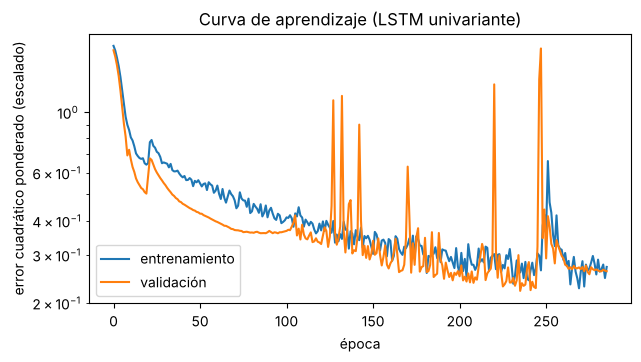

In [ ]:
plt.figure(figsize=(7, 3.5))
plt.plot(hist_uni.history['loss'], label='entrenamiento')
plt.plot(hist_uni.history['val_loss'], label='validación')
plt.xlabel('época'); plt.ylabel('error cuadrático ponderado (escalado)'); plt.yscale('log'); plt.legend()
plt.title('Curva de aprendizaje (LSTM univariante)')
plt.show()

## 5. Evaluación de un modelo en test

Deshacemos el z-score (multiplicar por la desviación y sumar la media) para pasar las predicciones a casos. Cada ventana predice 28 días, así que juntamos las ventanas de la temporada y calculamos las métricas por tramos de la salida: días 1-7, 8-14 y 15-28.

Definiciones:
- **MAE:** error absoluto medio, en casos al día
- **RMSE:** raíz del error cuadrático medio, en casos al día.
- **WAPE:** suma de los errores absolutos dividida entre la suma de los casos observados, en porcentaje.
- **Día y magnitud del pico:** evaluar cuándo y cuánto es el pico


In [ ]:
GRUPOS = {'días 1-7': slice(0, 7), 'días 8-14': slice(7, 14), 'días 15-28': slice(14, 28)}
H_PICO = [7, 28]       # horizontes (días de antelación) con los que se mira el pico

def predecir(modelo, datos, conjunto, t_test=None):
    """Predicciones de los 28 días en casos (se deshace el z-score). Devuelve origen, observado y predicho."""
    v = datos['val'] if conjunto == 'val' else datos['test'][t_test]
    pred = modelo.predict(entradas(v), verbose=0) * v['sigma'] + v['mu']
    obs = v['Y'] * v['sigma'] + v['mu']
    return v['origen'], obs, pred

def referencia_semana(origen):
    """Referencia: para cada día a predecir, el mismo día de la semana en la última semana observada.
    Para el día 7 es lo que pasó hace 7 días."""
    pos0 = df.index.get_indexer(origen)
    h = np.arange(1, N_SALIDA + 1)
    idx = pos0[:, None] + h[None, :] - 7 * np.ceil(h / 7).astype(int)[None, :]
    return df['casos'].to_numpy()[idx]

def metricas(origen, obs, pred):
    """MAE, RMSE y WAPE por tramos de la salida, y día y magnitud del pico a 7 y a 28 días de antelación."""
    m = {}
    for g, sl in GRUPOS.items():
        e = pred[:, sl] - obs[:, sl]
        m[f'MAE {g}'] = np.abs(e).mean()
        m[f'RMSE {g}'] = np.sqrt((e ** 2).mean())
        m[f'WAPE {g} (%)'] = np.abs(e).sum() / obs[:, sl].sum() * 100
    for h in H_PICO:
        dias = origen + pd.Timedelta(days=h)            # días cuya predicción se hizo h días antes
        o, p = obs[:, h - 1], pred[:, h - 1]
        m[f'dif. día pico a {h} d (días)'] = (dias[p.argmax()] - dias[o.argmax()]).days
        m[f'dif. magnitud pico a {h} d (casos)'] = p.max() - o.max()
    return pd.Series(m)

COLS_PICO = [f'dif. día pico a {h} d (días)' for h in H_PICO] + [f'dif. magnitud pico a {h} d (casos)' for h in H_PICO]
COLS_MAE = [f'MAE {g}' for g in GRUPOS]
COLS_RMSE = [f'RMSE {g}' for g in GRUPOS]
COLS_WAPE = [f'WAPE {g} (%)' for g in GRUPOS]

# validación (solo para ver cómo va) y test, con el modelo de la semilla 1
resultados_uni = {}
for nombre, conjunto, t_test in [(f'Validación {TEMP_VAL}', 'val', None)] + [(f'Test {t}', 'test', t) for t in TEMP_TEST]:
    origen, obs, pred = predecir(modelo_uni, datos_uni, conjunto, t_test)
    ref = referencia_semana(origen)
    if t_test:
        resultados_uni[t_test] = (origen, obs, pred, ref)
    tabla = pd.DataFrame({'LSTM univariante': metricas(origen, obs, pred), 'Referencia': metricas(origen, obs, ref)}).T
    print(f'--- {nombre} ---')
    print(tabla[COLS_MAE + COLS_RMSE + COLS_WAPE].round(1).to_string())
    print(tabla[COLS_PICO].round(1).to_string())


--- Validación 2016-17 ---
                  MAE días 1-7  MAE días 8-14  MAE días 15-28  RMSE días 1-7  RMSE días 8-14  RMSE días 15-28  WAPE días 1-7 (%)  WAPE días 8-14 (%)  WAPE días 15-28 (%)
LSTM univariante          85.6           85.1           103.7          213.1           199.4            220.7               32.9                32.8                 40.1
Referencia               102.0          163.5           261.1          280.9           415.8            609.2               39.3                63.0                101.0
                  dif. día pico a 7 d (días)  dif. día pico a 28 d (días)  dif. magnitud pico a 7 d (casos)  dif. magnitud pico a 28 d (casos)
LSTM univariante                         0.0                          7.0                            -199.1                            -1352.1
Referencia                               7.0                         28.0                               0.0                                0.0
--- Test 2017-18 ---
             

--- Test 2018-19 ---
                  MAE días 1-7  MAE días 8-14  MAE días 15-28  RMSE días 1-7  RMSE días 8-14  RMSE días 15-28  WAPE días 1-7 (%)  WAPE días 8-14 (%)  WAPE días 15-28 (%)
LSTM univariante         405.1          718.9          1186.5          718.0          1270.1           1934.3               69.1               122.7                202.7
Referencia               197.8          374.9           605.1          382.4           712.3           1096.7               33.8                64.0                103.4
                  dif. día pico a 7 d (días)  dif. día pico a 28 d (días)  dif. magnitud pico a 7 d (casos)  dif. magnitud pico a 28 d (casos)
LSTM univariante                         0.0                         64.0                             506.2                              773.3
Referencia                               7.0                         28.0                               0.0                                0.0


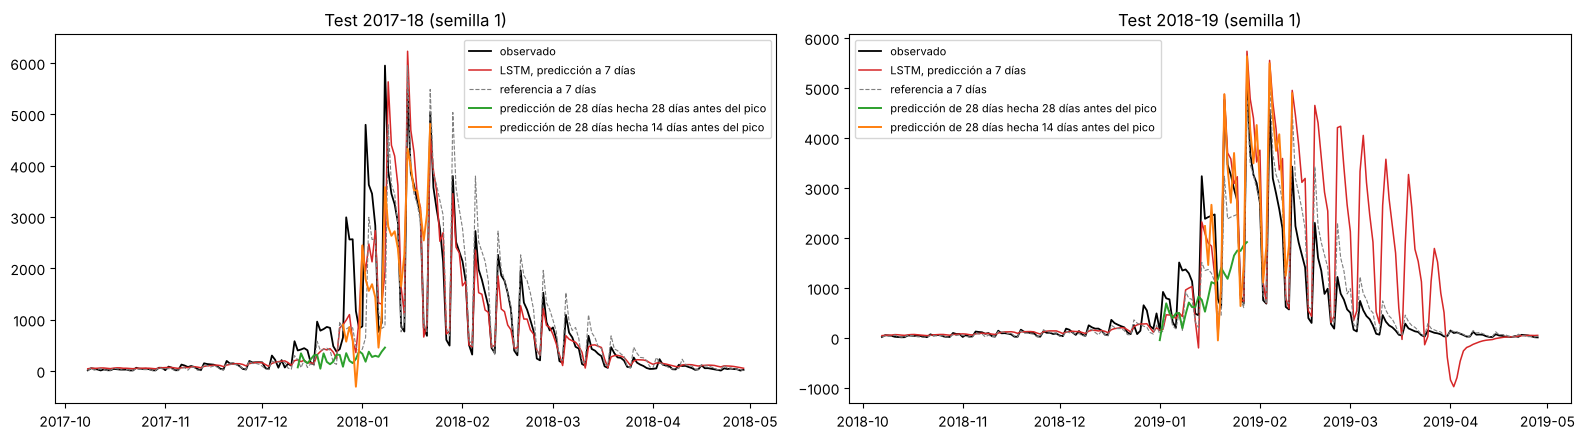

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4.5))
for a, (t_test, (origen, obs, pred, ref)) in zip(ax, resultados_uni.items()):
    dias7 = origen + pd.Timedelta(days=7)
    a.plot(dias7, obs[:, 6], color='k', lw=1.3, label='observado')
    a.plot(dias7, pred[:, 6], color='tab:red', lw=1.1, label='LSTM, predicción a 7 días')
    a.plot(dias7, ref[:, 6], color='tab:gray', lw=.8, ls='--', label='referencia a 7 días')
    pico = dias7[obs[:, 6].argmax()]
    for dias_antes, col in [(28, 'tab:green'), (14, 'tab:orange')]:        # predicciones de 28 días hechas antes del pico
        i = np.where(origen == pico - pd.Timedelta(days=dias_antes))[0]
        if len(i):
            i = i[0]
            a.plot(origen[i] + pd.to_timedelta(np.arange(1, N_SALIDA + 1), unit='D'), pred[i], color=col, lw=1.4,
                   label=f'predicción de 28 días hecha {dias_antes} días antes del pico')
    a.set_title(f'Test {t_test} (semilla 1)'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()


## 6. Robustez: repetición con varias semillas


In [ ]:
SEMILLAS = [1, 2, 3, 4, 5]

def robustez(cols_seq, cols_cal=(), semillas=SEMILLAS):
    """Entrena una red por semilla y guarda las métricas en cada temporada de test."""
    datos = preparar(cols_seq, cols_cal)
    filas = {t: [] for t in TEMP_TEST}
    preds = {}
    for s in semillas:
        m, _ = entrenar(datos, semilla=s)
        for t_test in TEMP_TEST:
            origen, obs, pred = predecir(m, datos, 'test', t_test)
            preds[(t_test, s)] = pred
            filas[t_test].append(metricas(origen, obs, pred))
    tablas = {t: pd.DataFrame(f, index=[f'semilla {s}' for s in semillas]) for t, f in filas.items()}
    return tablas, preds

def resumen(tablas, columnas):
    """Media ± desviación típica de las semillas, una fila por temporada de test."""
    return pd.DataFrame({t: {c: f'{r[c].mean():.1f} ± {r[c].std():.1f}' for c in columnas}
                         for t, r in tablas.items()}).T

met_ref = {}
for t in TEMP_TEST:
    origen, obs, _ = predecir(modelo_uni, datos_uni, 'test', t)
    met_ref[t] = metricas(origen, obs, referencia_semana(origen))

rob_uni, preds_uni = robustez(['casos_esc'])


Entrenadas las 5 semillas del modelo univariante. Los resultados están en las tablas de la sección 16.


# PARTE 3. Pre-procesado de las variables de día y festivo

## 7. Variables que se crean

- `dow_lun` ... `dow_dom`: Día de la semana en one-hot: 7 columnas binarias, una vale 1 y las otras seis valen 0.
- `festivo`: 1 si es festivo oficial de Cataluña (librería `holidays`, subdivisión `CT`) o si está entre el 23 de diciembre y el 6 de enero. Si no, 0.
- `post_festivo`: 1 si es el primer día no festivo después de un festivo o de un bloque de festivos seguidos. Si no, 0.

**Día de la semana en one-hot.**

**Festivo y post-festivo.** Son dos variables binarias. `festivo` incluye los festivos oficiales y todos los días de Navidad (del 23/12 al 6/1). `post_festivo` marca el día en que se vuelve a la normalidad después de un festivo. Hemos mirado el efecto en los datos para comprobar que merece la pena añadirlos.

In [ ]:
# día de la semana en one-hot
df['dia_semana'] = df.index.dayofweek
DIAS = ['lun', 'mar', 'mie', 'jue', 'vie', 'sab', 'dom']
for k, d in enumerate(DIAS):
    df[f'dow_{d}'] = (df['dia_semana'] == k).astype(int)
DOW = [f'dow_{d}' for d in DIAS]

# festivos oficiales de Cataluña y periodo navideño (23/12 - 6/1)
años = range(df.index.year.min(), df.index.year.max() + 1)
fest = holidays.Spain(subdiv='CT', years=años)
df['festivo_oficial'] = df.index.isin(pd.to_datetime(list(fest.keys()))).astype(int)
md_ = df.index.month * 100 + df.index.day
df['navidad'] = ((md_ >= 1223) | (md_ <= 106)).astype(int)
df['festivo'] = ((df['festivo_oficial'] == 1) | (df['navidad'] == 1)).astype(int)

# primer día no festivo tras un festivo (o tras un bloque de festivos seguidos)
df['post_festivo'] = ((df['festivo'].shift(1, fill_value=0) == 1) & (df['festivo'] == 0)).astype(int)

print('Cada día solo tiene una columna de día de la semana a 1:', bool((df[DOW].sum(axis=1) == 1).all()))
print('Días festivo:', int(df['festivo'].sum()), '| días post_festivo:', int(df['post_festivo'].sum()))
print('\nComprobación: Viernes Santo y Lunes de Pascua ya son festivos oficiales en Cataluña')
for a in [2018, 2019]:
    p = pd.Timestamp(easter(a))
    for off_, nombre in [(-2, 'Viernes Santo'), (1, 'Lunes de Pascua')]:
        dia = p + pd.Timedelta(days=off_)
        print(f'  {a} {nombre} {dia.date()}: festivo_oficial =', int(df.loc[dia, 'festivo_oficial']))
print('\nEjemplo (diciembre de 2025), solo las variables que entran a la red:')
print(df.loc['2025-12-05':'2025-12-10', DOW + ['festivo', 'post_festivo', 'casos']])

Cada día solo tiene una columna de día de la semana a 1: True
Días festivo: 361 | días post_festivo: 151

Comprobación: Viernes Santo y Lunes de Pascua ya son festivos oficiales en Cataluña
  2018 Viernes Santo 2018-03-30: festivo_oficial = 1
  2018 Lunes de Pascua 2018-04-02: festivo_oficial = 1
  2019 Viernes Santo 2019-04-19: festivo_oficial = 1
  2019 Lunes de Pascua 2019-04-22: festivo_oficial = 1

Ejemplo (diciembre de 2025), solo las variables que entran a la red:
            dow_lun  dow_mar  dow_mie  dow_jue  dow_vie  dow_sab  dow_dom  \
fecha                                                                       
2025-12-05        0        0        0        0        1        0        0   
2025-12-06        0        0        0        0        0        1        0   
2025-12-07        0        0        0        0        0        0        1   
2025-12-08        1        0        0        0        0        0        0   
2025-12-09        0        1        0        0        0       

### 8. Por qué el día de la semana va en one-hot

Primero miramos el perfil semanal: los casos de cada día divididos entre el nivel local (media de 15 días centrada), solo en temporada pre-pandemia y sin festivos. Un valor de 1 es "igual que el nivel de esos días". Luego comparamos cuánta variación explica cada codificación en un ajuste lineal sencillo (R², de 0 a 1).


Perfil semanal (casos / nivel local): {'lun': 1.65, 'mar': 1.33, 'mie': 1.25, 'jue': 1.13, 'vie': 0.97, 'sab': 0.35, 'dom': 0.29}
R2 seno/coseno solo             : 0.53
R2 solo fin de semana (sí/no)   : 0.72
R2 seno/coseno + fin de semana  : 0.82
R2 día de la semana con one hot    : 0.86


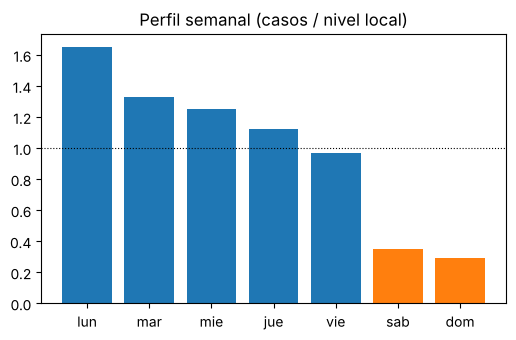

In [ ]:
nivel = df['casos'].where(df['valido']).rolling(15, center=True, min_periods=8).mean()
s = df[(df['periodo'] == 'pre') & (df['en_temporada'] == 1) & df['valido'] & (df['festivo'] == 0)].copy()
s['r'] = s['casos'] / nivel.reindex(s.index)
s = s.dropna(subset=['r'])

perfil = s.groupby('dia_semana')['r'].mean()
print('Perfil semanal (casos / nivel local):', dict(zip(DIAS, perfil.round(2))))

plt.figure(figsize=(6, 3.5))
plt.bar(DIAS, perfil.values, color=['tab:blue'] * 5 + ['tab:orange'] * 2)
plt.axhline(1, color='k', lw=.8, ls=':')
plt.title('Perfil semanal (casos / nivel local)'); plt.show()


## 9. Efecto de los festivos en los datos

Comparar los casos medios de un festivo con los de un día normal confunde, porque los festivos caen en momentos distintos de la epidemia. Por eso comparamos cada día con su entorno: dividimos sus casos entre la media de los laborables normales de unos días alrededor (ventana centrada de 15 días). Un valor de 1 significa "igual que lo normal" y 0,26 significa "una cuarta parte de lo normal". Usamos solo laborables, de temporada y pre-pandemia, para que el fin de semana y la pandemia no distorsionen.

La tabla incluye también grupos que no entran como variable, para ver qué efecto queda fuera.

                                                  días  ratio medio
festivo oficial (variable festivo)                71.0         0.26
Navidad sin festivo oficial (variable festivo)    61.0         0.94
   de ellos, 24 y 31 de diciembre                 10.0         0.65
   de ellos, resto                                51.0         1.00
día posterior (variable post_festivo)             38.0         1.17
víspera (pre_festivo, no incluida)                45.0         0.74
Semana Santa festivo (Vie. Santo / L. Pascua)     16.0         0.34
Semana Santa no festivo (no incluida)             32.0         0.77
resto de laborables                             1091.0         0.99


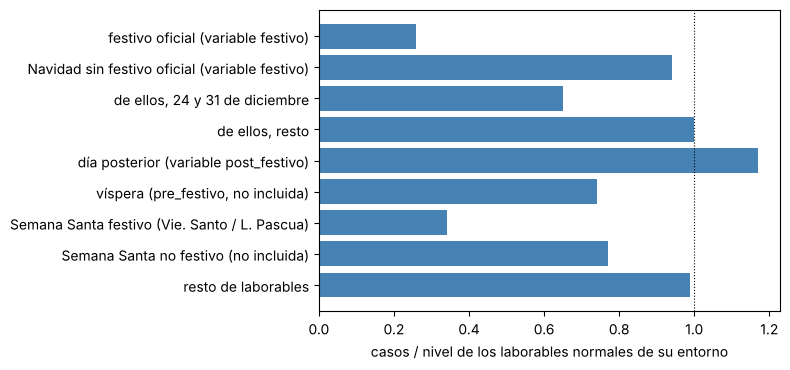

In [ ]:
an = df[['casos', 'dia_semana', 'en_temporada', 'periodo', 'festivo', 'festivo_oficial', 'navidad', 'post_festivo']].copy()
an['pre_festivo'] = ((an['festivo'].shift(-1, fill_value=0) == 1) & (an['festivo'] == 0)).astype(int)
an['semana_santa'] = 0
for a in años:
    p = pd.Timestamp(easter(a))
    an.loc[p - pd.Timedelta(days=7): p + pd.Timedelta(days=1), 'semana_santa'] = 1

# nivel de referencia: media móvil de los laborables normales del entorno
lab = (an['dia_semana'] < 5) & (an['festivo_oficial'] == 0)
base = an['casos'].where(lab).rolling(15, center=True, min_periods=5).mean()
an['ratio'] = an['casos'] / base
e = an[(an['en_temporada'] == 1) & (an['periodo'] == 'pre') & (an['dia_semana'] < 5)]

nav = (an['navidad'] == 1) & (an['festivo_oficial'] == 0)
grupos = {
    'festivo oficial (festivo)': an['festivo_oficial'] == 1,
    'Navidad sin festivo oficial (festivo)': nav,
    'día posterior (post_festivo)': an['post_festivo'] == 1,
    'víspera (no incluida)': an['pre_festivo'] == 1,
    'Semana Santa festivo': (an['semana_santa'] == 1) & (an['festivo_oficial'] == 1),
    'Semana Santa no festivo (no incluida)': (an['semana_santa'] == 1) & (an['festivo_oficial'] == 0),
    'resto de laborables': (an[['festivo', 'post_festivo', 'pre_festivo', 'semana_santa']] == 0).all(axis=1),
}
tabla = pd.DataFrame({n: {'días': e.loc[m.reindex(e.index), 'ratio'].dropna().size,
                          'ratio medio': round(e.loc[m.reindex(e.index), 'ratio'].mean(), 2)}
                      for n, m in grupos.items()}).T
print(tabla)

ax = tabla['ratio medio'][::-1].plot.barh(figsize=(8, 3.5), color='steelblue')
ax.axvline(1, color='k', lw=.8, ls=':')
ax.set_xlabel('casos / nivel de los laborables normales de su entorno')
plt.tight_layout(); plt.show()

## 10. Guardado del pre-procesado


In [ ]:
df_final = df.drop(columns=['festivo_oficial', 'navidad', 'casos_esc'], errors='ignore')
df_final.to_csv(SALIDA)
chequeo = pd.read_csv(SALIDA, index_col='fecha', parse_dates=['fecha'])
pd.testing.assert_frame_equal(chequeo, df_final, check_freq=False, check_dtype=False)
print('Guardado y releído sin cambios:', SALIDA)
print('Columnas:', list(df_final.columns))

Guardado y releído sin cambios: /home/claude/work/nb4/serie_diaria_con_calendario.csv
Columnas: ['casos', 'valido', 'semana_iso', 'en_temporada', 'temporada', 'periodo', 'dia_semana', 'dow_lun', 'dow_mar', 'dow_mie', 'dow_jue', 'dow_vie', 'dow_sab', 'dow_dom', 'festivo', 'post_festivo']


# PARTE 4. LSTM multivariante, primera variación

Ahora el modelo recibe, además de los casos, el día de la semana y los festivos.

## 11. Qué cambia respecto al univariante

Para que la comparación sea justa, todo lo demás se queda igual: misma partición por fechas, mismos cortes, ventana de 365 días de entrada y 28 de salida, pérdida ponderada, z-score, arquitectura, entrenamiento y semillas. Solo cambian las entradas:

- **Entrada A (secuencia):** para cada día de la ventana, los casos con z-score y 9 variables de calendario (7 del día de la semana, `festivo` y `post_festivo`). Forma: 365 días × 10 variables. Las variables de calendario son 0 o 1 y no se les aplica el z-score.
- **Entrada B (calendario de los 28 días a predecir):** las mismas 9 variables, pero de cada día que se predice (28 × 9 = 252 valores), que se unen a la salida de la capa LSTM antes de la capa densa.

Para decidir si mejora, comparamos medias y desviaciones de las cinco semillas y, semilla a semilla, la diferencia entre los dos modelos. Una mejora solo cuenta si es mayor que la variación entre semillas.

In [ ]:
CAL = DOW + ['festivo', 'post_festivo']
datos_cal = preparar(['casos_esc'] + CAL, CAL)
print('Forma de la secuencia:', datos_cal['ent']['S'].shape, '| calendario de los 28 días a predecir:', datos_cal['ent']['F'].shape)

t0 = time.time()
modelo_cal, hist_cal = entrenar(datos_cal, semilla=1)
modelo_cal.summary()
seg_cal = time.time() - t0
print('Épocas entrenadas:', len(hist_cal.history['loss']),
      '| mejor error de validación:', round(min(hist_cal.history['val_loss']), 5),
      '(univariante:', round(min(hist_uni.history['val_loss']), 5), f') | tiempo: {time.time() - t0:.0f} s')


Forma de la secuencia: (1435, 365, 10) | calendario de los 28 días a predecir: (1435, 252)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ secuencia           │ (None, 365, 10)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 32)        │      5,504 │ secuencia[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ calendario_objetivo │ (None, 252)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 284)       │          0 │ lstm[0][0],       │
│ (Concatenate)       │                   │            │ calendario_objet… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │      4,560 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 28)        │        476 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 31,622 (123.53 KB)

 Trainable params: 10,540 (41.17 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 21,082 (82.36 KB)

Épocas entrenadas: 227 | mejor error de validación: 0.16608 (univariante: 0.22123 ) | tiempo: 500 s


--- Test 2017-18 (semilla 1) ---
                     MAE días 1-7  MAE días 8-14  MAE días 15-28  RMSE días 1-7  RMSE días 8-14  RMSE días 15-28  WAPE días 1-7 (%)  WAPE días 8-14 (%)  WAPE días 15-28 (%)
LSTM con calendario         243.9          255.9           351.4          452.3           500.7            737.3               32.0                33.6                 46.1
LSTM univariante            249.4          283.4           385.1          503.8           568.6            795.3               32.7                37.2                 50.6
Referencia                  238.5          428.6           705.5          585.8           878.5           1221.5               31.3                56.3                 92.6
                     dif. día pico a 7 d (días)  dif. día pico a 28 d (días)  dif. magnitud pico a 7 d (casos)  dif. magnitud pico a 28 d (casos)
LSTM con calendario                         7.0                         14.0                           -1101.4                   

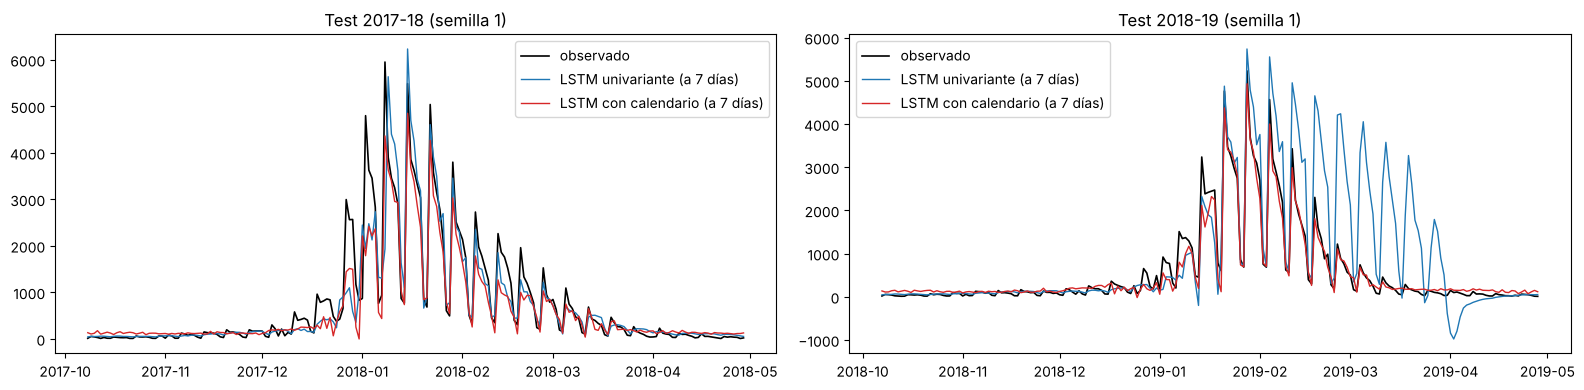

In [ ]:
resultados_cal = {}
for t_test in TEMP_TEST:
    origen, obs, pred = predecir(modelo_cal, datos_cal, 'test', t_test)
    resultados_cal[t_test] = pred
    tabla = pd.DataFrame({'LSTM con calendario': metricas(origen, obs, pred),
                          'LSTM univariante': metricas(origen, obs, resultados_uni[t_test][2]),
                          'Referencia': metricas(origen, obs, resultados_uni[t_test][3])}).T
    print(f'--- Test {t_test} (semilla 1) ---')
    print(tabla[COLS_MAE + COLS_RMSE + COLS_WAPE].round(1).to_string())
    print(tabla[COLS_PICO].round(1).to_string())

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for a, t_test in zip(ax, TEMP_TEST):
    origen, obs, pred_uni, ref = resultados_uni[t_test]
    dias7 = origen + pd.Timedelta(days=7)
    a.plot(dias7, obs[:, 6], color='k', lw=1.2, label='observado')
    a.plot(dias7, pred_uni[:, 6], color='tab:blue', lw=1, label='LSTM univariante (a 7 días)')
    a.plot(dias7, resultados_cal[t_test][:, 6], color='tab:red', lw=1, label='LSTM con calendario (a 7 días)')
    a.set_title(f'Test {t_test} (semilla 1)'); a.legend()
plt.tight_layout(); plt.show()


## 12. Comparación con varias semillas

Igual que con el univariante, entrenamos el modelo con calendario con las mismas cinco semillas y comparamos en test.


In [ ]:
rob_cal, preds_cal = robustez(['casos_esc'] + CAL, CAL)


Entrenadas las 5 semillas del modelo con calendario. Los resultados están en las tablas de la sección 16.


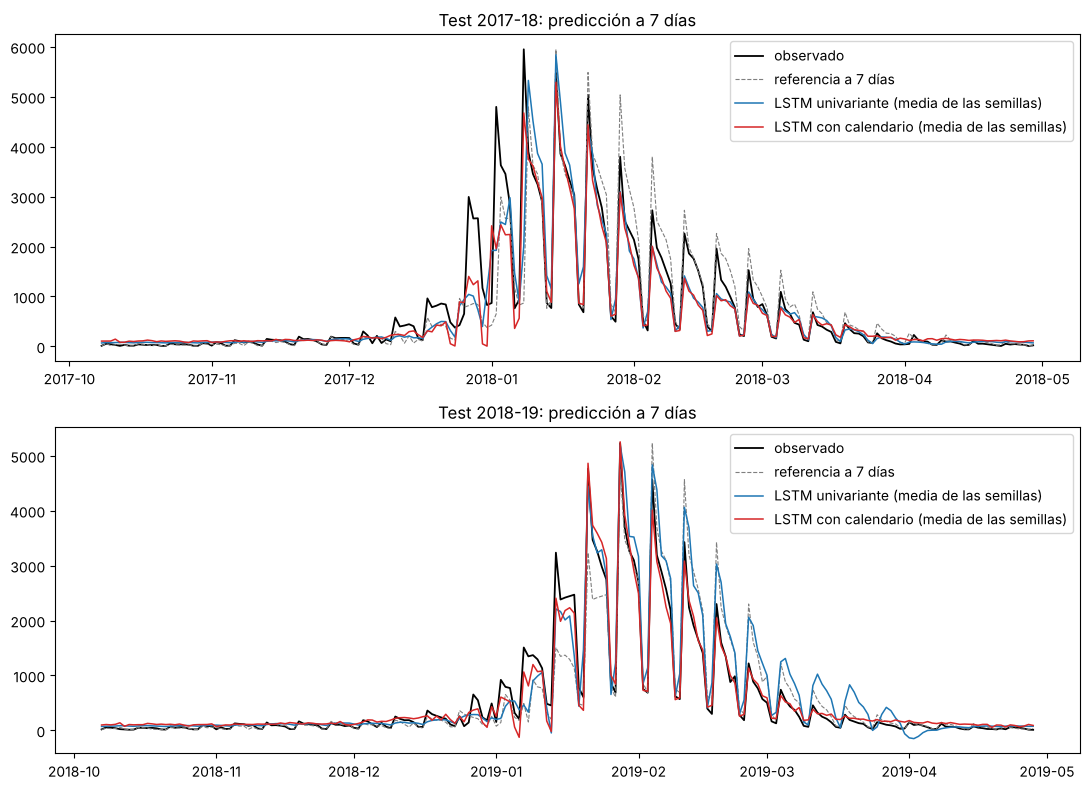

In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(11, 8))
for a, t_test in zip(ax, TEMP_TEST):
    origen = datos_uni['test'][t_test]['origen']
    dias7 = origen + pd.Timedelta(days=7)
    obs = df.loc[dias7, 'casos'].to_numpy()
    media_uni = np.mean([preds_uni[(t_test, s)][:, 6] for s in SEMILLAS], axis=0)
    media_cal = np.mean([preds_cal[(t_test, s)][:, 6] for s in SEMILLAS], axis=0)
    a.plot(dias7, obs, color='k', lw=1.3, label='observado')
    a.plot(dias7, referencia_semana(origen)[:, 6], color='tab:gray', lw=.8, ls='--', label='referencia a 7 días')
    a.plot(dias7, media_uni, color='tab:blue', lw=1.1, label='LSTM univariante (media de las semillas)')
    a.plot(dias7, media_cal, color='tab:red', lw=1.1, label='LSTM con calendario (media de las semillas)')
    a.set_title(f'Test {t_test}: predicción a 7 días'); a.legend()
plt.tight_layout(); plt.show()


# PARTE 5. Tablas de resultados

## 13. Tablas de resultados



In [ ]:
from IPython.display import display

TRAMOS = ['1-7', '8-14', '15-28']
MODELOS = [('Referencia', None), ('LSTM univariante', rob_uni), ('LSTM con calendario', rob_cal)]

def num(x, dec=1, signo=False):
    """Número con formato español (coma decimal y punto de millares)."""
    s = f'{abs(x):,.{dec}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')
    if round(x, dec) < 0:
        return '−' + s
    return ('+' + s) if signo and round(x, dec) > 0 else s

def media_sd(serie, dec=1, signo=False):
    """Media ± desviación típica de las cinco semillas."""
    return f'{num(serie.mean(), dec, signo)} ± {num(serie.std(), dec)}'

def estilo(df, titulo):
    """Tabla al estilo de un artículo: título arriba y solo líneas horizontales."""
    return (df.style.set_caption(titulo).set_table_styles([
        {'selector': 'caption', 'props': [('caption-side', 'top'), ('font-weight', 'bold'), ('text-align', 'left'), ('padding-bottom', '6px')]},
        {'selector': '', 'props': [('border-collapse', 'collapse'), ('border-top', '2px solid currentColor'), ('border-bottom', '2px solid currentColor')]},
        {'selector': 'thead th', 'props': [('text-align', 'center'), ('border-bottom', '1px solid currentColor')]},
        {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '2px 10px'), ('white-space', 'nowrap')]},
        {'selector': 'th', 'props': [('padding', '2px 10px')]},
        {'selector': 'th.row_heading', 'props': [('text-align', 'left'), ('font-weight', 'normal'), ('white-space', 'nowrap')]}]))

def filas(funcion):
    """Una fila por temporada de test y modelo (referencia, univariante, calendario)."""
    datos, idx = [], []
    for t in TEMP_TEST:
        for nombre, rob in MODELOS:
            datos.append(funcion(t, rob)); idx.append((f'Temporada {t}', nombre))
    return datos, pd.MultiIndex.from_tuples(idx)


In [ ]:
def f(t, rob):
    return [num(met_ref[t][f'{m} días {g}']) if rob is None else media_sd(rob[t][f'{m} días {g}'])
            for m in ('MAE', 'RMSE') for g in TRAMOS]
datos, idx = filas(f)
cab = pd.MultiIndex.from_tuples([(m, f'Días {g}') for m in ('MAE (casos al día)', 'RMSE (casos al día)') for g in TRAMOS])
display(estilo(pd.DataFrame(datos, index=idx, columns=cab),
               'Tabla 1. MAE y RMSE por tramo de la predicción en las temporadas de test (media ± desviación típica de 5 semillas; la referencia no depende de la semilla).'))


<pandas Styler>

In [ ]:
def f(t, rob):
    wape = [num(met_ref[t][f'WAPE días {g} (%)']) if rob is None else media_sd(rob[t][f'WAPE días {g} (%)']) for g in TRAMOS]
    mejor = ['–'] * 3 if rob is None else [f"{int((rob[t][f'MAE días {g}'] < met_ref[t][f'MAE días {g}']).sum())}/5" for g in TRAMOS]
    return wape + mejor
datos, idx = filas(f)
cab = pd.MultiIndex.from_tuples([('WAPE (%)', f'Días {g}') for g in TRAMOS] + [('Semillas con MAE menor que la referencia', f'Días {g}') for g in TRAMOS])
display(estilo(pd.DataFrame(datos, index=idx, columns=cab),
               'Tabla 2. WAPE por tramo de la predicción y número de semillas (de 5) que superan a la referencia.'))


<pandas Styler>

In [ ]:
filas3 = []
for m in ('MAE', 'RMSE', 'WAPE'):
    sufijo = ' (%)' if m == 'WAPE' else ''
    filas3.append([f"{sum(int((rob_cal[t][f'{m} días {g}{sufijo}'].values < rob_uni[t][f'{m} días {g}{sufijo}'].values).sum()) for t in TEMP_TEST)}/10"
                   for g in TRAMOS])
display(estilo(pd.DataFrame(filas3, index=['MAE', 'RMSE', 'WAPE'], columns=[f'Días {g}' for g in TRAMOS]),
               'Tabla 3. Comparaciones (de 10: 5 semillas × 2 temporadas) en las que el modelo con calendario tiene menos error que el univariante con la misma semilla.'))


,Días 1-7,Días 8-14,Días 15-28
MAE,8/10,10/10,9/10
RMSE,9/10,9/10,9/10
WAPE,8/10,10/10,9/10


In [ ]:
def f(t, rob):
    if rob is None:
        return [num(met_ref[t][c], 0, True) for c in COLS_PICO_ORDEN]
    return [media_sd(rob[t][c], 0 if 'magnitud' in c else 1, True) for c in COLS_PICO_ORDEN]
COLS_PICO_ORDEN = ['dif. día pico a 7 d (días)', 'dif. magnitud pico a 7 d (casos)', 'dif. día pico a 28 d (días)', 'dif. magnitud pico a 28 d (casos)']
datos, idx = filas(f)
cab = pd.MultiIndex.from_tuples([('Predicción a 7 días', 'Día (días)'), ('Predicción a 7 días', 'Magnitud (casos)'),
                                 ('Predicción a 28 días', 'Día (días)'), ('Predicción a 28 días', 'Magnitud (casos)')])
display(estilo(pd.DataFrame(datos, index=idx, columns=cab),
               'Tabla 4. Diferencia entre el pico predicho y el observado (día: positivo = tardío; magnitud: negativo = subestimado).'))


<pandas Styler>

In [ ]:
def fila_entrenamiento(modelo, hist, seg):
    vl = np.array(hist.history['val_loss'])
    n_par = sum(int(np.prod(w.shape)) for w in modelo.trainable_weights)
    return [num(n_par, 0), num(len(vl), 0), num(int(vl.argmin()) + 1, 0), num(vl.min(), 3), num(seg, 0)]
display(estilo(pd.DataFrame([fila_entrenamiento(modelo_uni, hist_uni, seg_uni), fila_entrenamiento(modelo_cal, hist_cal, seg_cal)],
                            index=['LSTM univariante', 'LSTM con calendario'],
                            columns=['Parámetros entrenables', 'Épocas', 'Mejor época', 'Error de validación', 'Tiempo (s)']),
               'Tabla 5. Entrenamiento de la semilla 1 de cada modelo (error cuadrático medio ponderado, en valores escalados).'))


,Parámetros entrenables,Épocas,Mejor época,Error de validación,Tiempo (s)
LSTM univariante,5.356,286,236,"0,221",610
LSTM con calendario,10.540,227,177,"0,166",500
